In [1]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
import random
import torch

In [2]:
# set seeds 
np.random.seed(1)
torch.manual_seed(1)
random.seed(1)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
'''work_folder = input()
saving_folder = input()'''
work_folder = 'lcc'
saving_folder = 'prova'
os.chdir(work_folder)

In [5]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../..")))
from ddqn.buffer import *

pygame 2.5.2 (SDL 2.28.2, Python 3.10.12)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [6]:
file_path = saving_folder + '/' + 'parameters.txt'  # Path to the parameters file

parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 1
Lx = 32
Ly = 32
delta = 0.3
beta = 4.5
eta = 0.0
decay_rate = 0.015
n_special = 200
t_transient = 0
tmax = 1000
eta_special = 0.07
batch_size = 64
gamma = 0.99
max_size = 1000000
state_dim = (3, 5, 5)
action_dim = 8
action_bound = 1
critic_lr = 0.0001
tau = 0.001
weight_decay = 0.1
epsilon_decay = 0.9999
epsilon_min = 0.01
target_upd_steps = 20
epsilon_start = 1


In [7]:
env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])

buffer = ReplayBuffer(max_size, state_dim, action_dim)

In [8]:
from ddqn_ants import *
config_net_file = f"{saving_folder}/networks.yaml"
ddqn_ants = DDQN_ants(env, buffer,
                 gamma, action_bound, critic_lr, tau, batch_size, epsilon_decay, weight_decay, config_net_file,
                 target_upd_steps, epsilon_min, epsilon_start)
        

In [9]:
ddqn_ants.setup_networks()

if not os.path.exists(saving_folder + '/results'):
    os.makedirs(saving_folder + '/results')

if not os.path.exists(saving_folder + '/results_test'):
    os.makedirs(saving_folder + '/results_test')

if not os.path.exists(saving_folder + '/weights'):
    os.makedirs(saving_folder + '/weights')

with open(saving_folder + '/results/results.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/reward.txt', 'w') as file:
    file.write(f"")
    
'''with open(saving_folder + '/results/op.txt', 'w') as file:
    file.write(f"")'''
    
with open(saving_folder + '/results_test/reward.txt', 'w') as file:
    file.write(f"")

'''with open(saving_folder + '/results_test/op.txt', 'w') as file:
    file.write(f"")'''

with open(saving_folder + '/results/actor_weights.txt', 'w') as file:
    file.write(f"")

with open(saving_folder + '/results/critic_weights.txt', 'w') as file:
    file.write(f"")

/home/alessio/.local/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at ../aten/src/ATen/native/Convolution.cpp:1040.)
  return F.conv2d(input, weight, bias, self.stride,


In [10]:
print(ddqn_ants.critic)

CNN_critic(
  (cnn_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(2, 2), stride=(1, 1), padding=same)
    (1): ReLU()
  )
  (fc_layers): Sequential(
    (0): Linear(in_features=800, out_features=32, bias=True)
    (1): ReLU()
  )
  (output_layer): Linear(in_features=32, out_features=8, bias=True)
)


In [11]:
ddqn_ants.policy(np.random.uniform(0,1,(10,1,3,3)))

array([4, 4, 7, 2, 2, 6, 0, 1, 2, 6])

In [12]:
cw = ddqn_ants.compute_critic_weights()
indx_w_critic = []

for i in range(len(cw)):
    try:
        cw[i].numpy().shape[1]
        indx_w_critic.append(i)
    except:
        pass

In [13]:
epi = 0

In [14]:
while epi < 50000:
        
    score, act = ddqn_ants.training_episode()

    if epi %1 == 0:
        
        if epi %10 == 0:
                
            score_test, act_test, _ = ddqn_ants.test_episode()
                
            with open(saving_folder + '/results/reward.txt', 'a') as file:
                for item in score:
                    file.write(f"{item}\n")

            with open(saving_folder + '/results_test/reward.txt', 'a') as file:
                for item in score_test:
                    file.write(f"{np.mean(item)}\n")

        cw = ddqn_ants.compute_critic_weights()

        with open(saving_folder + '/results/critic_weights.txt', 'a') as f:
            f.write(str([cw[i].numpy().sum() for i in indx_w_critic]) + '\n')

        ddqn_ants.save_weights(saving_folder + '/weights')

    avg_score = np.mean(score)
    avg_a = np.mean(act)
    
    with open(saving_folder + '/results/results.txt', 'a') as f:
                    
        f.write(str(epi) + ' '  + str(avg_score) + ' ' + str(avg_a) + '\n')

    epi += 1 
    print('epsilon: ', ddqn_ants.epsilon, 'score: ', np.mean(score), end='\r')

KeyboardInterrupt: 

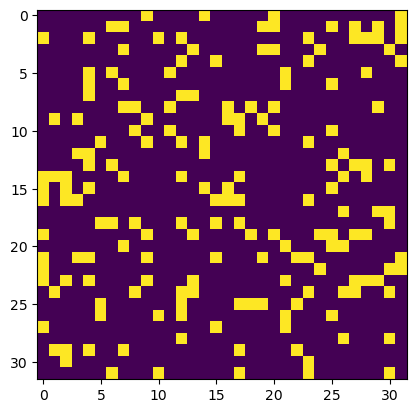

In [23]:
plt.imshow(ddqn_ants.env.pheromones > (2*env.s0))

In [ ]:
s,a,r,s1,d = ddqn_ants.replay_buffer.sample(1)
print(s.shape, a.shape, r.shape, s1.shape)

torch.Size([1, 3, 3, 3]) torch.Size([1, 1]) torch.Size([1, 1]) torch.Size([1, 3, 3, 3])


In [ ]:
ddqn_ants.replay_buffer.sample(1)

(tensor([[[[0.3251, 0.2804, 0.3066],
           [6.4541, 0.5539, 3.4078],
           [4.5762, 6.3746, 3.5727]],
 
          [[1.0000, 0.0000, 1.0000],
           [4.0000, 1.0000, 1.0000],
           [1.0000, 1.0000, 2.0000]],
 
          [[1.0000, 0.0000, 1.0000],
           [1.0000, 1.0000, 0.0000],
           [0.0000, 0.0000, 1.0000]]]]),
 tensor([[5.]]),
 tensor([[0.1833]]),
 tensor([[[[0.3936, 0.0949, 0.1656],
           [5.7285, 0.3271, 0.2762],
           [0.6823, 6.5717, 0.5525]],
 
          [[1.0000, 0.0000, 0.0000],
           [1.0000, 1.0000, 2.0000],
           [0.0000, 0.0000, 0.0000]],
 
          [[1.0000, 0.0000, 0.0000],
           [0.0000, 1.0000, 2.0000],
           [0.0000, 0.0000, 0.0000]]]]),
 tensor([[0.]]))

<AxesSubplot:>

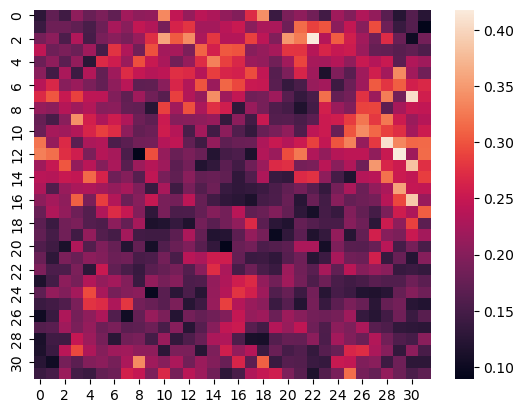

In [ ]:
import seaborn as sns
sns.heatmap(env.pheromones)